# Sesión 3 · Visualización exploratoria en Python
**Misión 9–11 nov 2026 · Lunes 9 · 15:30–17:00 · Santiago Quintana**

Notebook de **demostración** (primera mitad, ~45 min). En la segunda mitad trabajarán `S3_taller_estudiantes.ipynb`.

| Bloque | Min | Pregunta guía |
|---|---|---|
| 1. Criterios de selección | 8 | ¿Qué pregunta responde este gráfico? |
| 2. Distribuciones y categorías (`tips`) | 12 | ¿Cómo se reparten los valores? |
| 3. Relaciones entre variables (`penguins`) | 13 | ¿Qué se mueve con qué? |
| 4. Conteos vs porcentajes | 5 | ¿Comparo cantidades o proporciones? |
| 5. Interactividad y hallazgos | 7 | ¿Qué concluyo y qué NO puedo concluir? |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style="whitegrid", context="notebook")
tips = sns.load_dataset("tips")
tips["tip_pct"] = 100 * tips["tip"] / tips["total_bill"]
penguins = sns.load_dataset("penguins").dropna().reset_index(drop=True)
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]

## 1. Criterios de selección de gráficos

| Pregunta analítica | Tipo de variables | Gráfico recomendado | Evitar |
|---|---|---|---|
| ¿Cómo se distribuye una variable? | 1 continua | Histograma, KDE, boxplot | Barras de cada valor |
| ¿Cuántos hay de cada categoría? | 1 categórica | Barras (horizontales si hay muchas) | Pie con > 4 categorías |
| ¿Cambia la distribución entre grupos? | continua × categórica | Boxplot, violin, histogramas superpuestos | Solo comparar medias |
| ¿Cómo se componen los grupos? | categórica × categórica | Barras apiladas / 100 % | Tablas largas |
| ¿Se relacionan dos variables? | continua × continua | Scatter (+ tamaño/color = bubble) | Líneas que unen puntos sin orden |
| ¿Cómo se relacionan muchas? | varias continuas | Heatmap de correlación, pairplot | 15 scatter sueltos |

**Reglas de oro:** el eje de barras empieza en 0 · un color = un significado · etiquetas con unidades · menos es más (sin 3D, sin sombras).

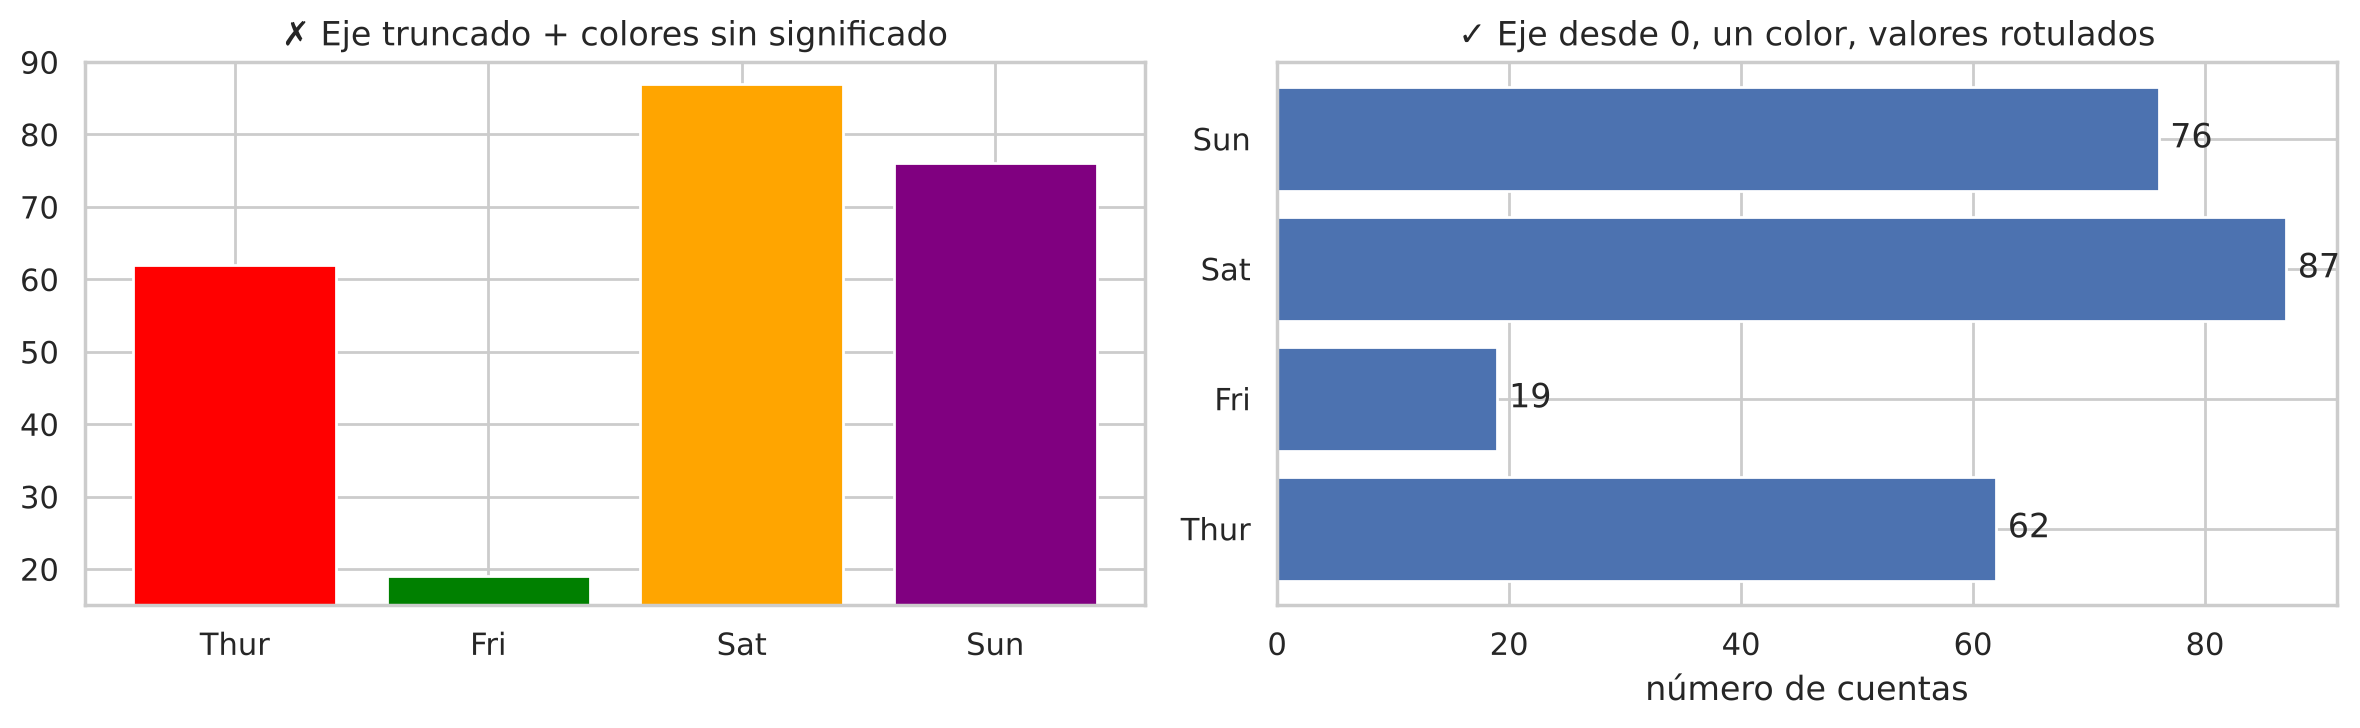

In [2]:
# Mal vs bien: el mismo dato, dos lecturas
conteo = tips["day"].value_counts().reindex(["Thur", "Fri", "Sat", "Sun"])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(conteo.index, conteo.values, color=["red", "green", "orange", "purple"])
axes[0].set_ylim(15, 90); axes[0].set_title("✗ Eje truncado + colores sin significado")
axes[1].barh(conteo.index, conteo.values, color="#4C72B0")
for y, v in enumerate(conteo.values):
    axes[1].text(v + 1, y, v, va="center")
axes[1].set_title("✓ Eje desde 0, un color, valores rotulados"); axes[1].set_xlabel("número de cuentas")
plt.tight_layout(); plt.show()

## 2. Distribuciones y categorías — `tips`
Variables: `total_bill` (USD), `tip` (USD), `tip_pct` (% propina), `sex`, `smoker`, `day`, `time`, `size`.

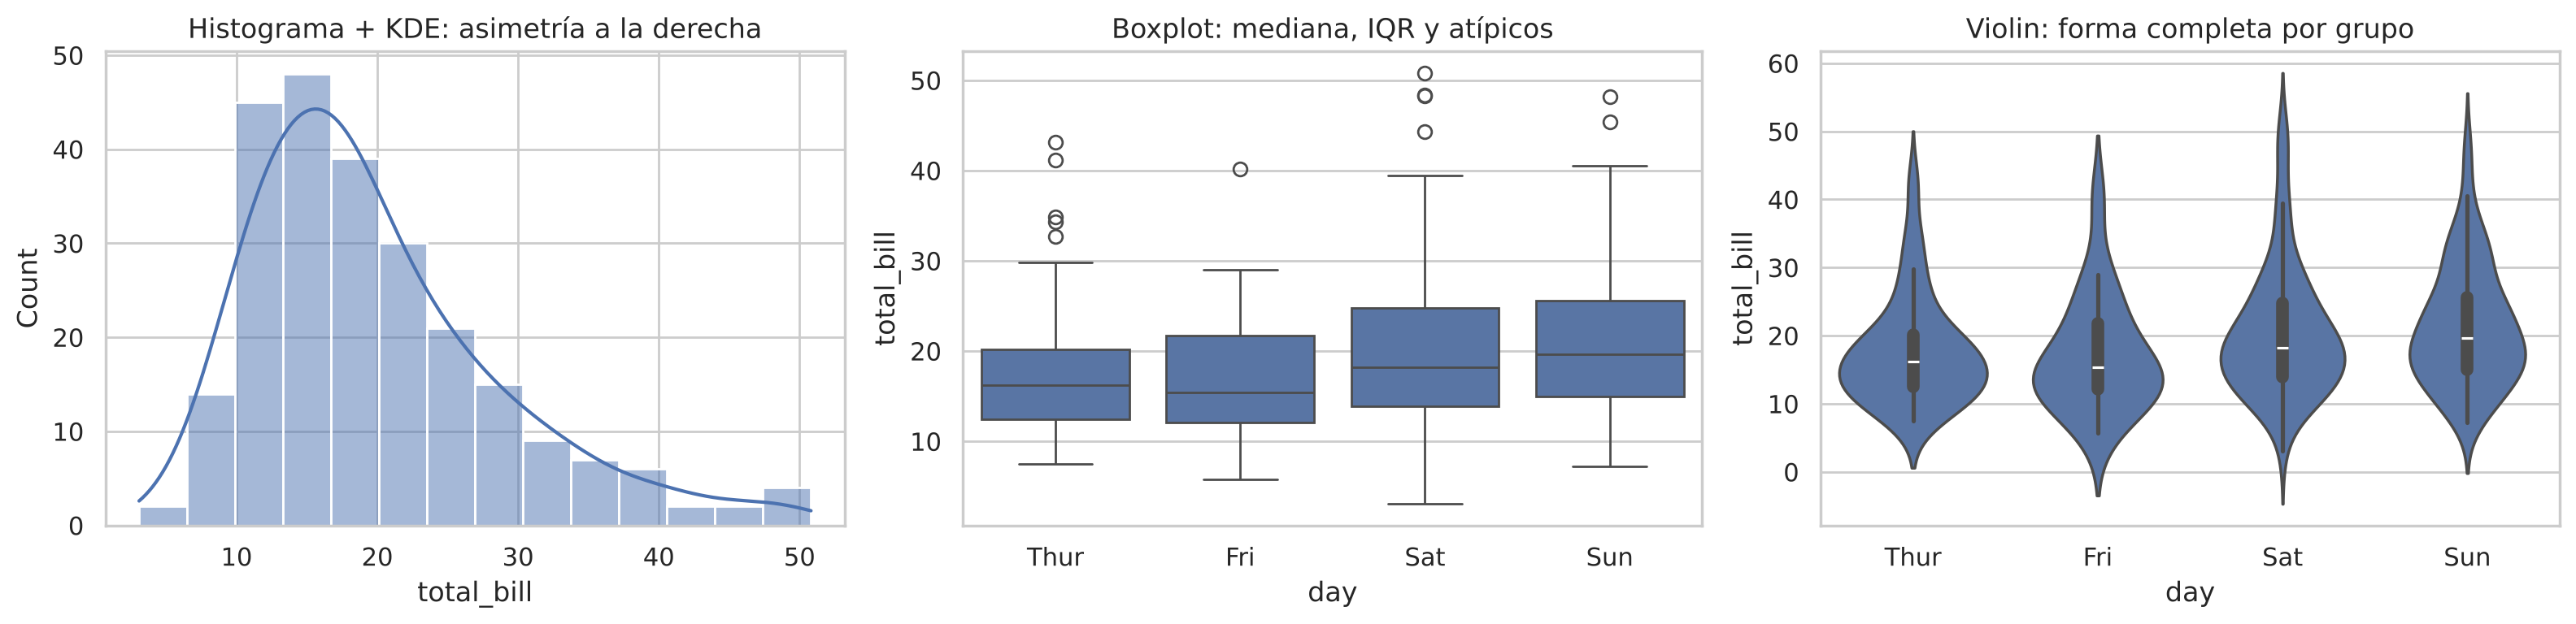

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(tips, x="total_bill", kde=True, ax=axes[0]).set_title("Histograma + KDE: asimetría a la derecha")
sns.boxplot(tips, x="day", y="total_bill", order=["Thur", "Fri", "Sat", "Sun"], ax=axes[1]).set_title("Boxplot: mediana, IQR y atípicos")
sns.violinplot(tips, x="day", y="total_bill", order=["Thur", "Fri", "Sat", "Sun"],
               ax=axes[2]).set_title("Violin: forma completa por grupo")
plt.tight_layout(); plt.show()

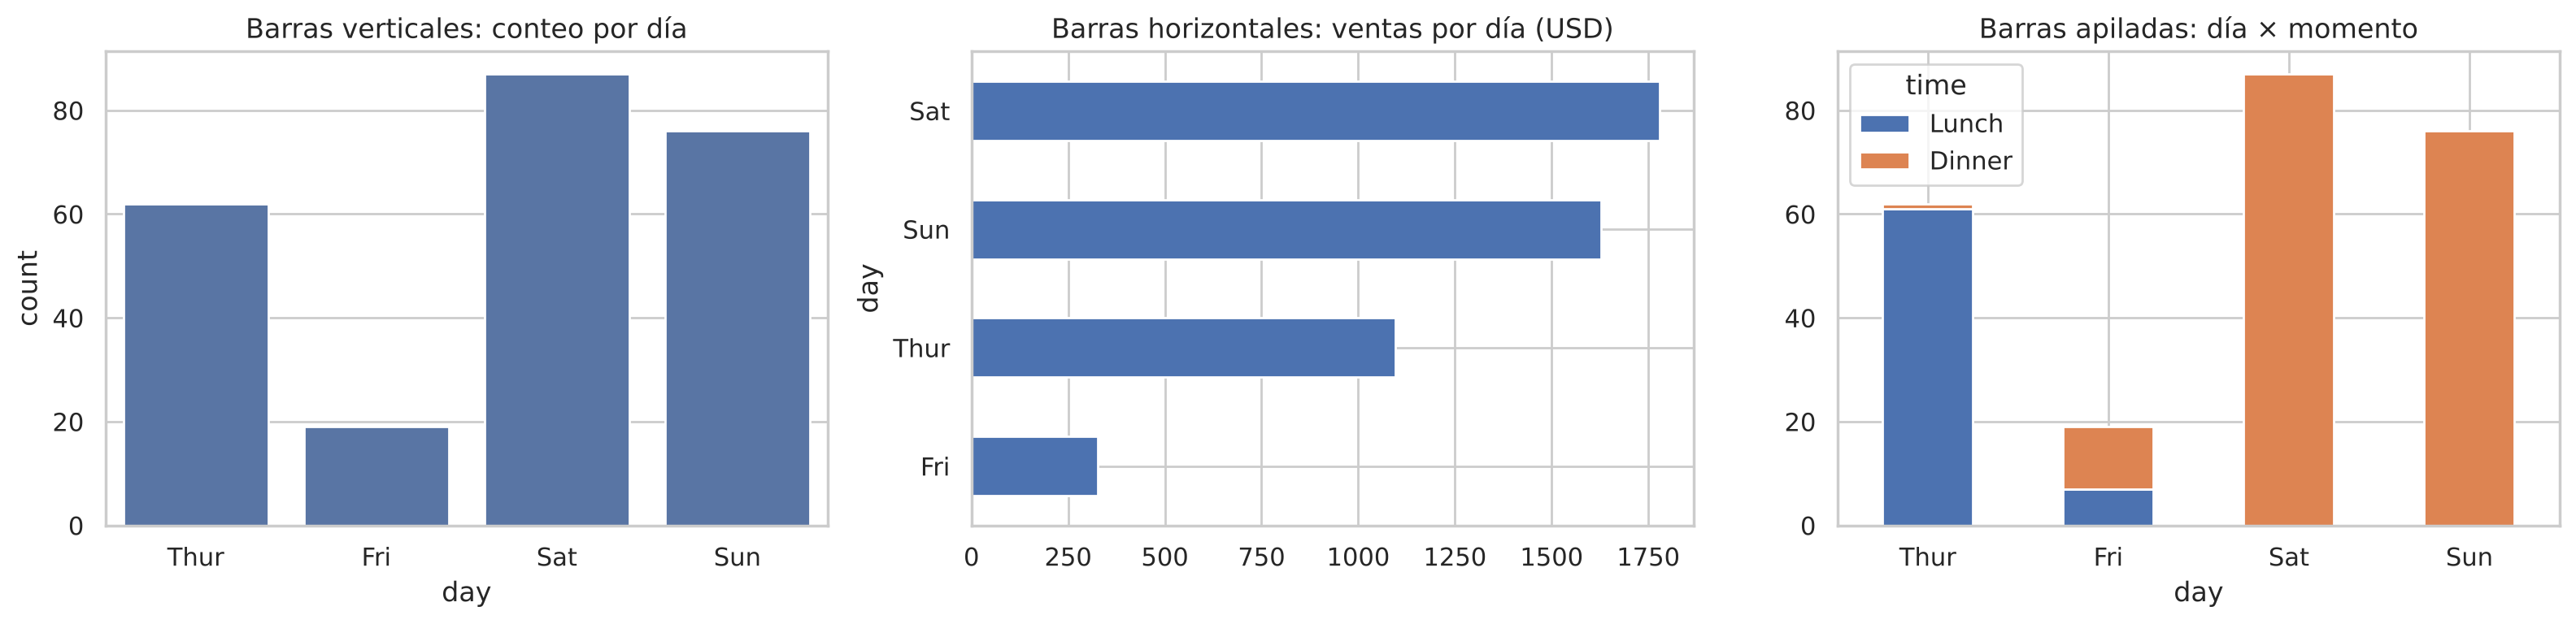

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.countplot(tips, x="day", order=["Thur", "Fri", "Sat", "Sun"], color="#4C72B0", ax=axes[0]).set_title("Barras verticales: conteo por día")
tips.groupby("day", observed=True)["total_bill"].sum().sort_values().plot.barh(ax=axes[1], color="#4C72B0")
axes[1].set_title("Barras horizontales: ventas por día (USD)")
pd.crosstab(tips["day"], tips["time"]).reindex(["Thur", "Fri", "Sat", "Sun"]).plot.bar(stacked=True, ax=axes[2], rot=0)
axes[2].set_title("Barras apiladas: día × momento")
plt.tight_layout(); plt.show()

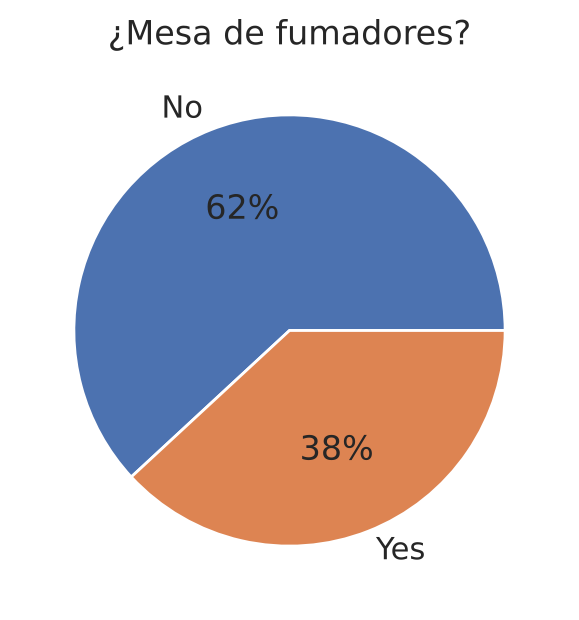

In [5]:
# Gráfico circular: SOLO con pocas categorías (aquí 2)
tips["smoker"].value_counts().plot.pie(autopct="%1.0f%%", figsize=(3.5, 3.5), ylabel="", title="¿Mesa de fumadores?")
plt.show()

## 3. Relaciones entre variables — `penguins`

**Correlación** (de −1 a 1): mide qué tanto dos variables se mueven juntas en línea recta.
- cerca de **1**: cuando una sube, la otra sube · cerca de **−1**: cuando una sube, la otra baja · cerca de **0**: no hay relación lineal.

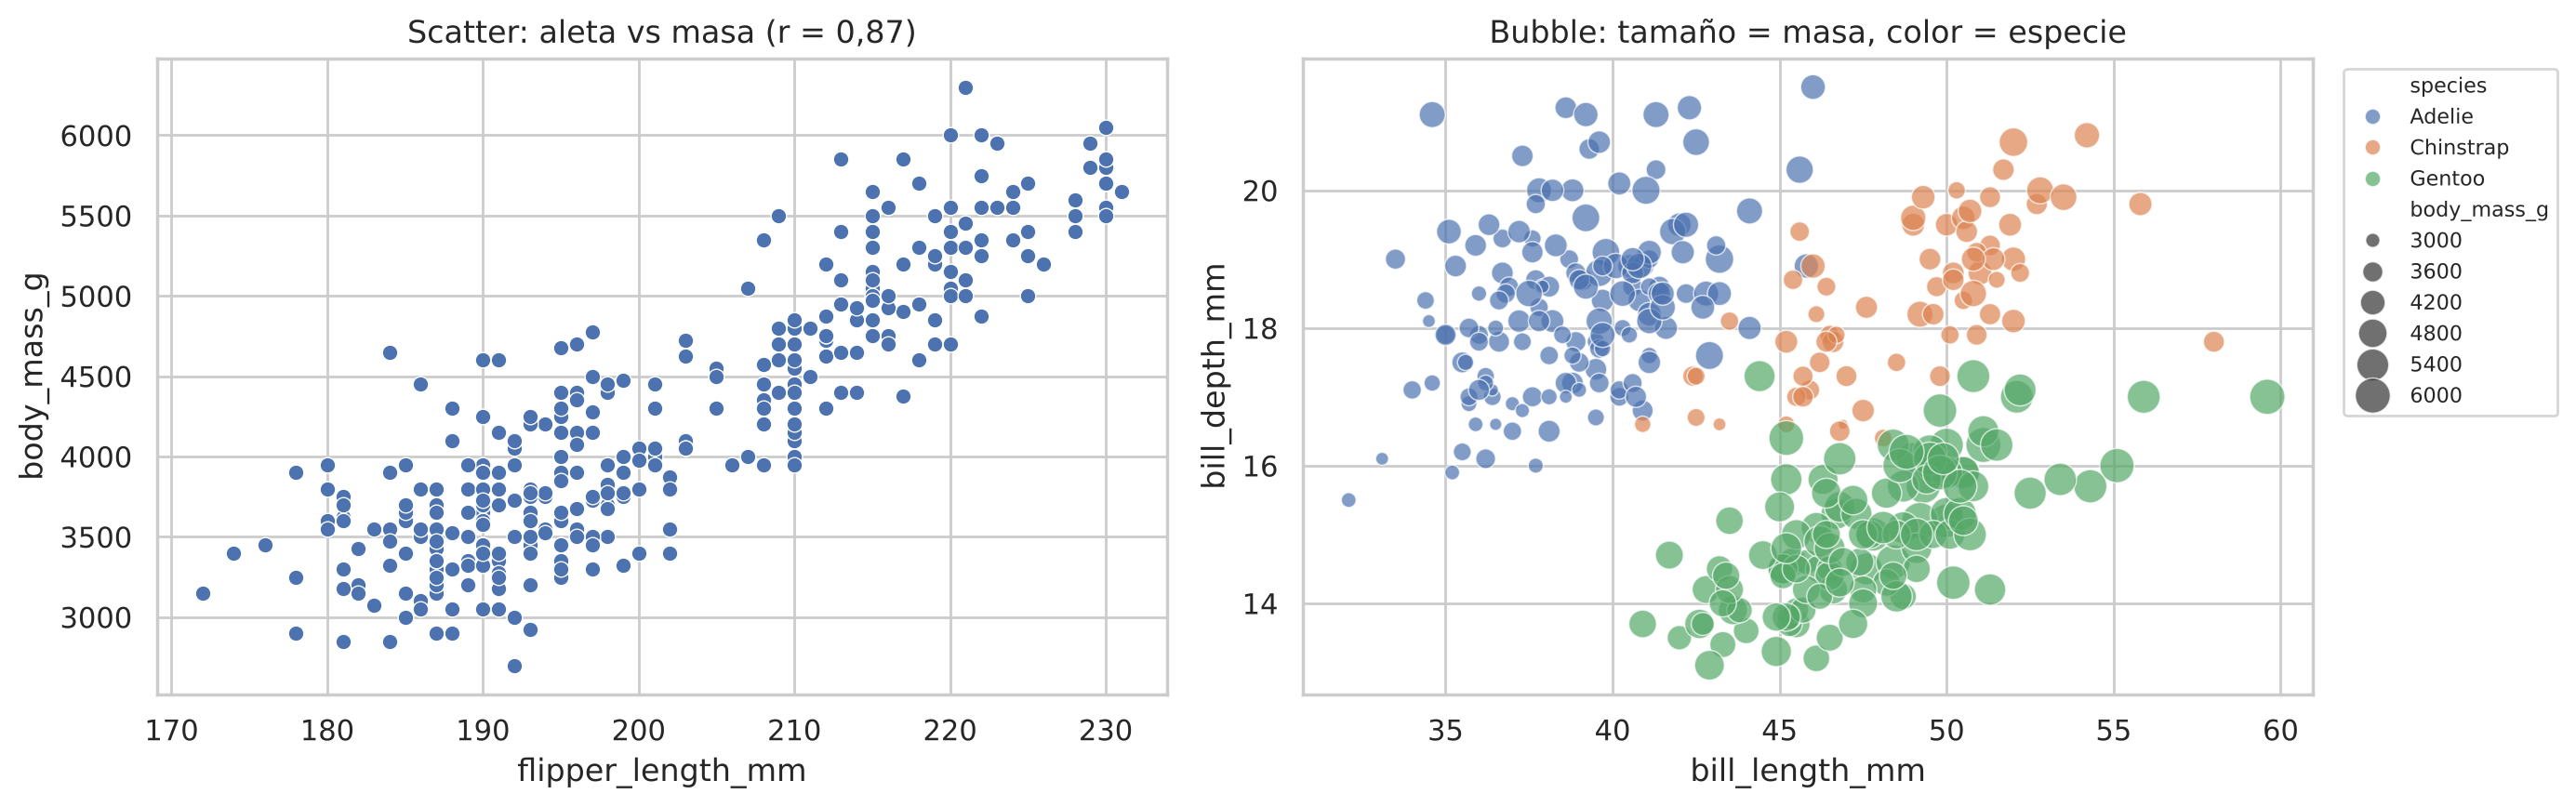

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.scatterplot(penguins, x="flipper_length_mm", y="body_mass_g", ax=axes[0]).set_title("Scatter: aleta vs masa (r = 0,87)")
sns.scatterplot(penguins, x="bill_length_mm", y="bill_depth_mm", hue="species", size="body_mass_g",
                sizes=(15, 200), alpha=0.7, ax=axes[1]).set_title("Bubble: tamaño = masa, color = especie")
axes[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

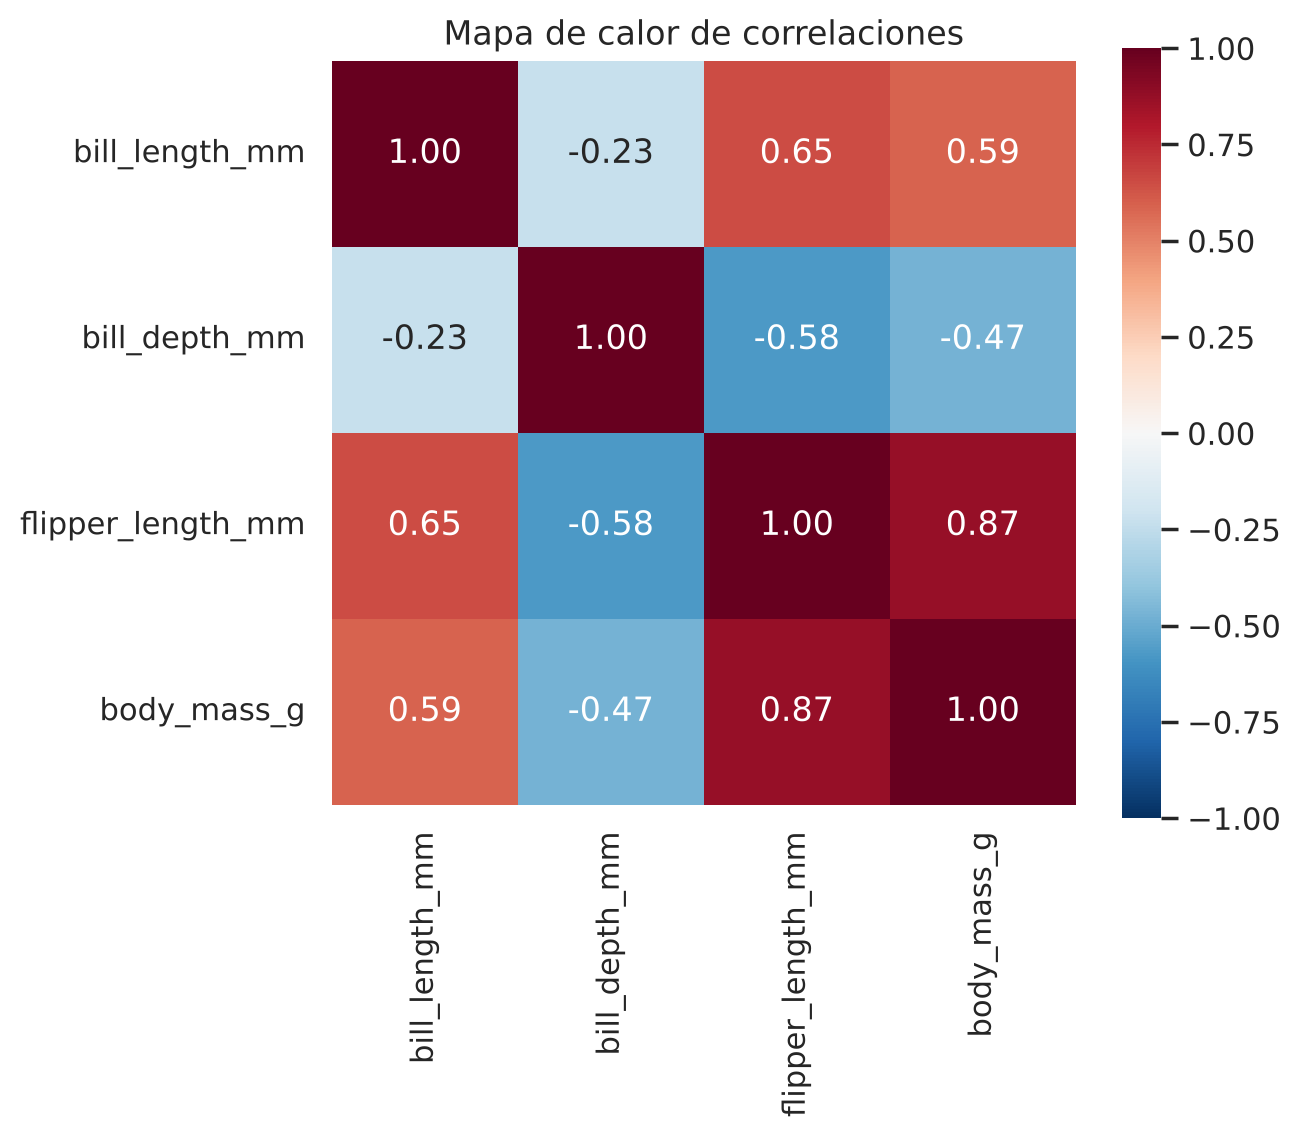

In [7]:
corr = penguins[num_cols].corr()
plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Mapa de calor de correlaciones"); plt.show()

> **Lectura:** aleta y masa (0,87) van muy de la mano: pingüinos con aletas largas pesan más. El mapa de calor resume todas las parejas en un solo gráfico.

### Pairplot: todas las parejas de variables de una vez

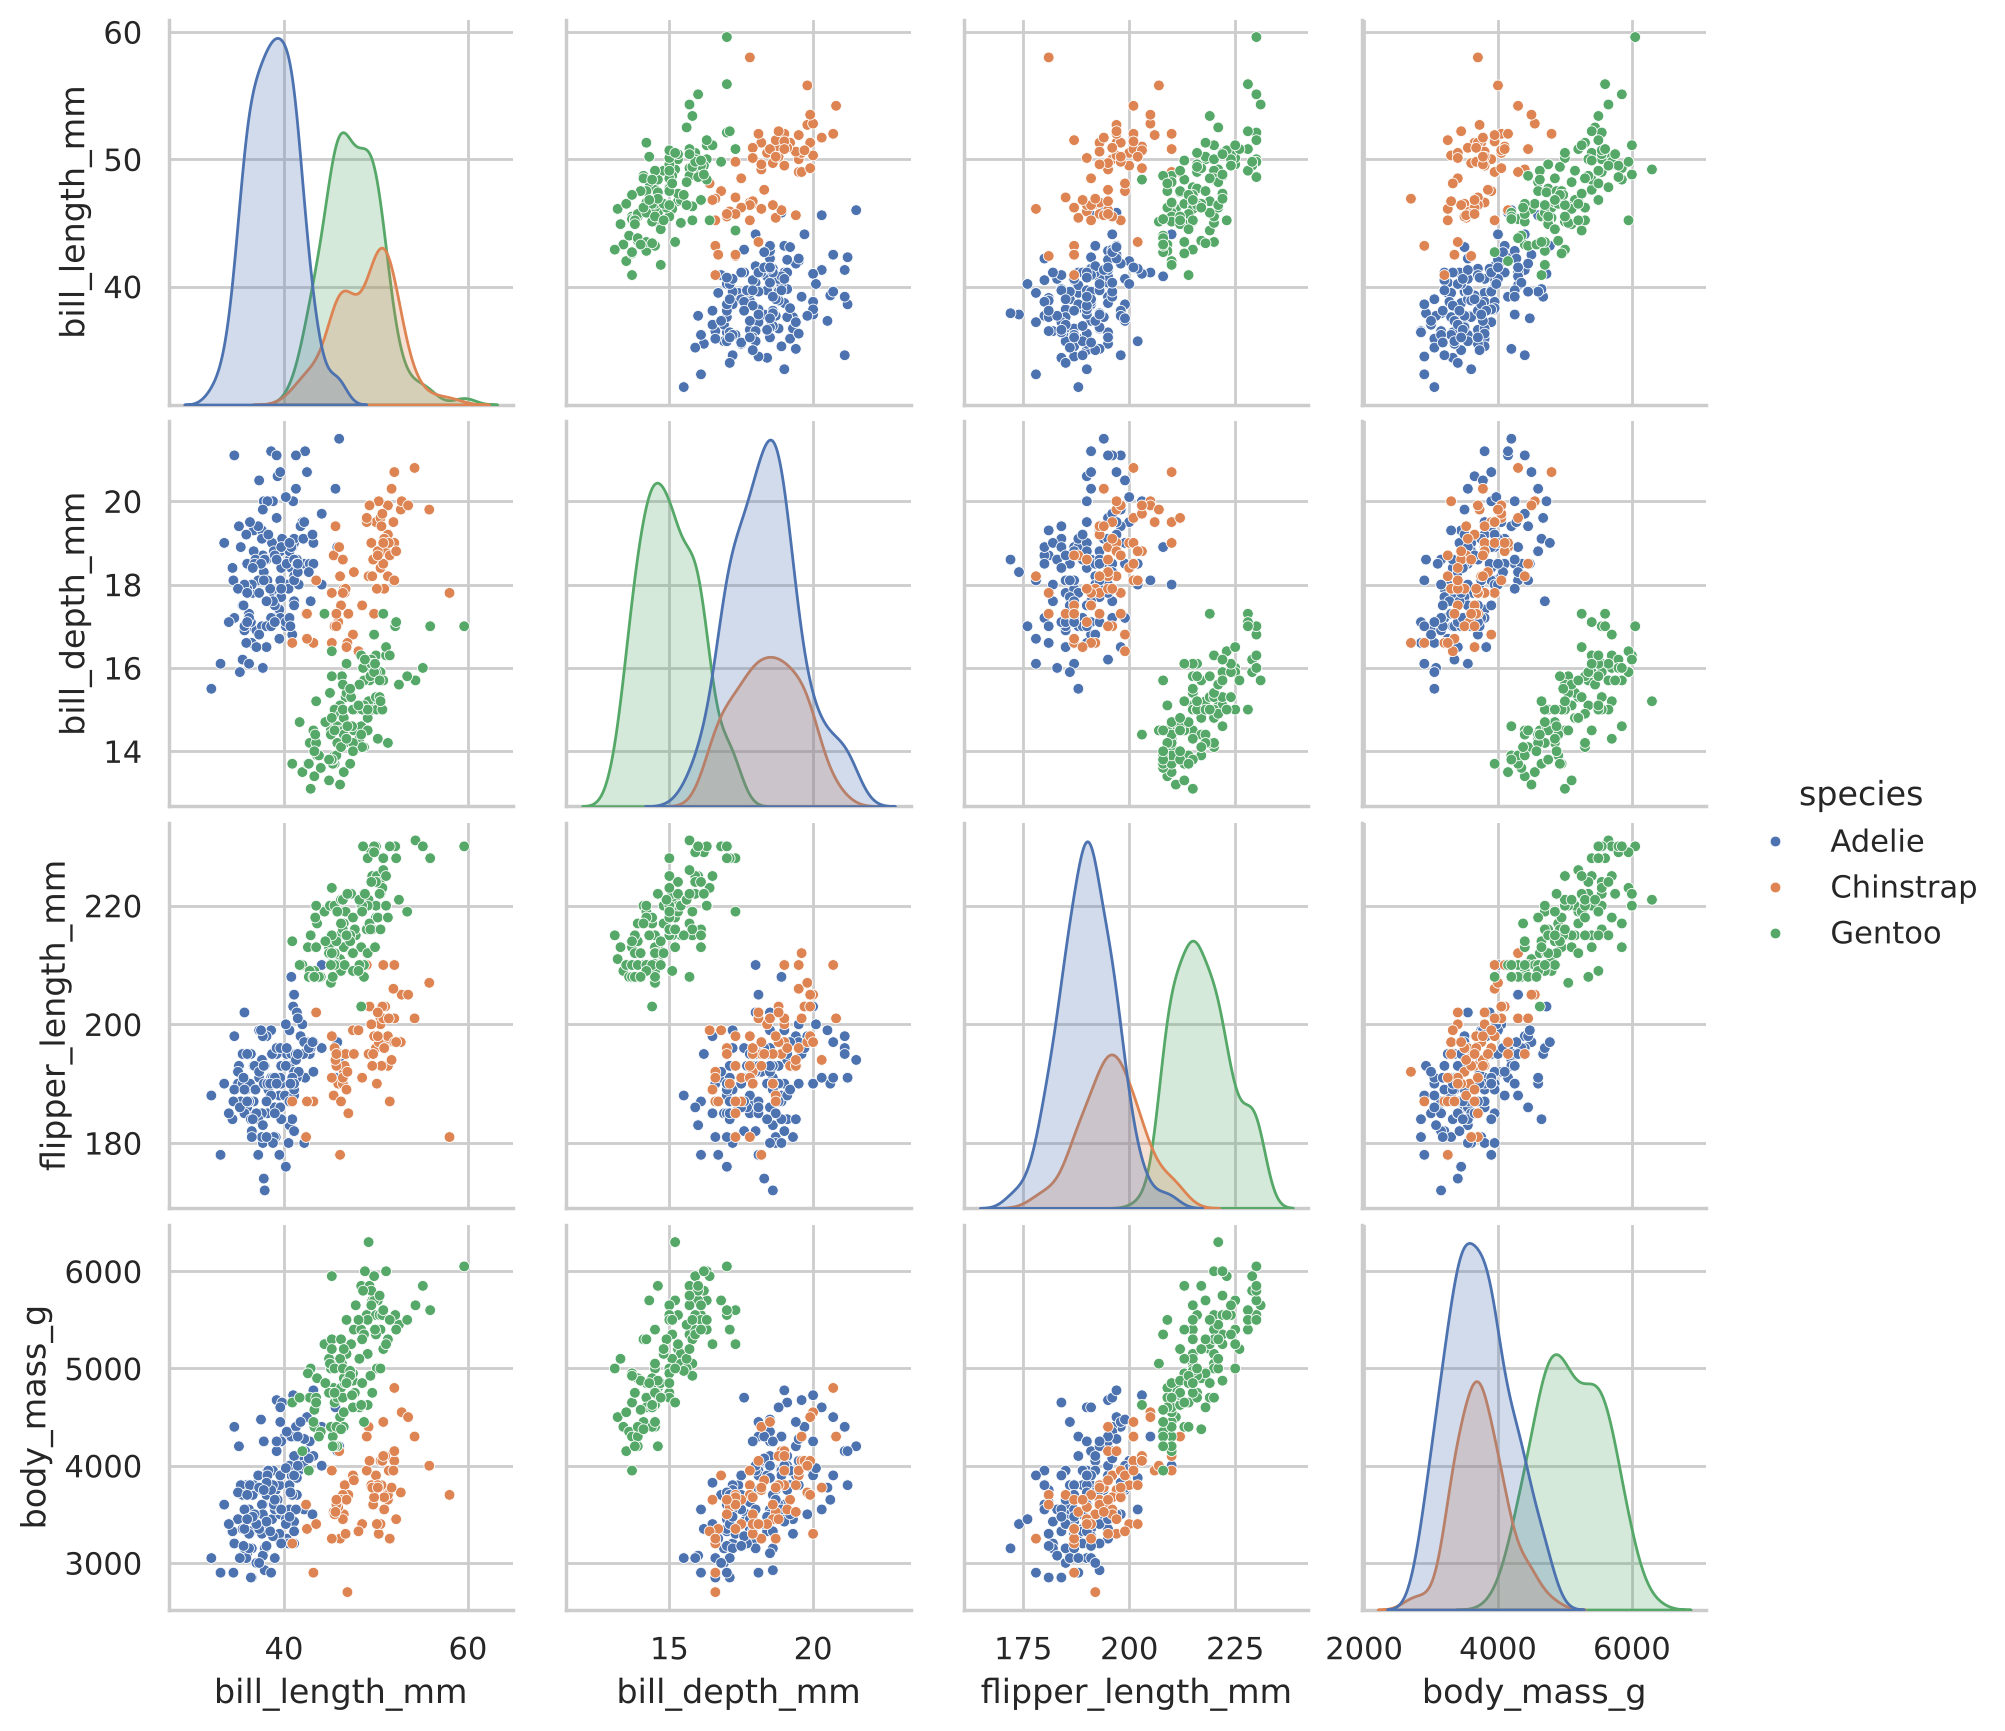

In [8]:
sns.pairplot(penguins[num_cols + ["species"]], hue="species", height=2.2, plot_kws={"s": 15})
plt.show()

> En la diagonal está la distribución de cada variable; fuera de ella, un scatter por cada pareja. Colorear por especie muestra que muchas "nubes" son en realidad 3 grupos.

## 4. Conteos vs porcentajes
Biscoe tiene más pingüinos que Torgersen. Los **conteos** responden "¿dónde hay más?"; los **porcentajes** responden "¿qué tan común es cada especie en cada isla?".

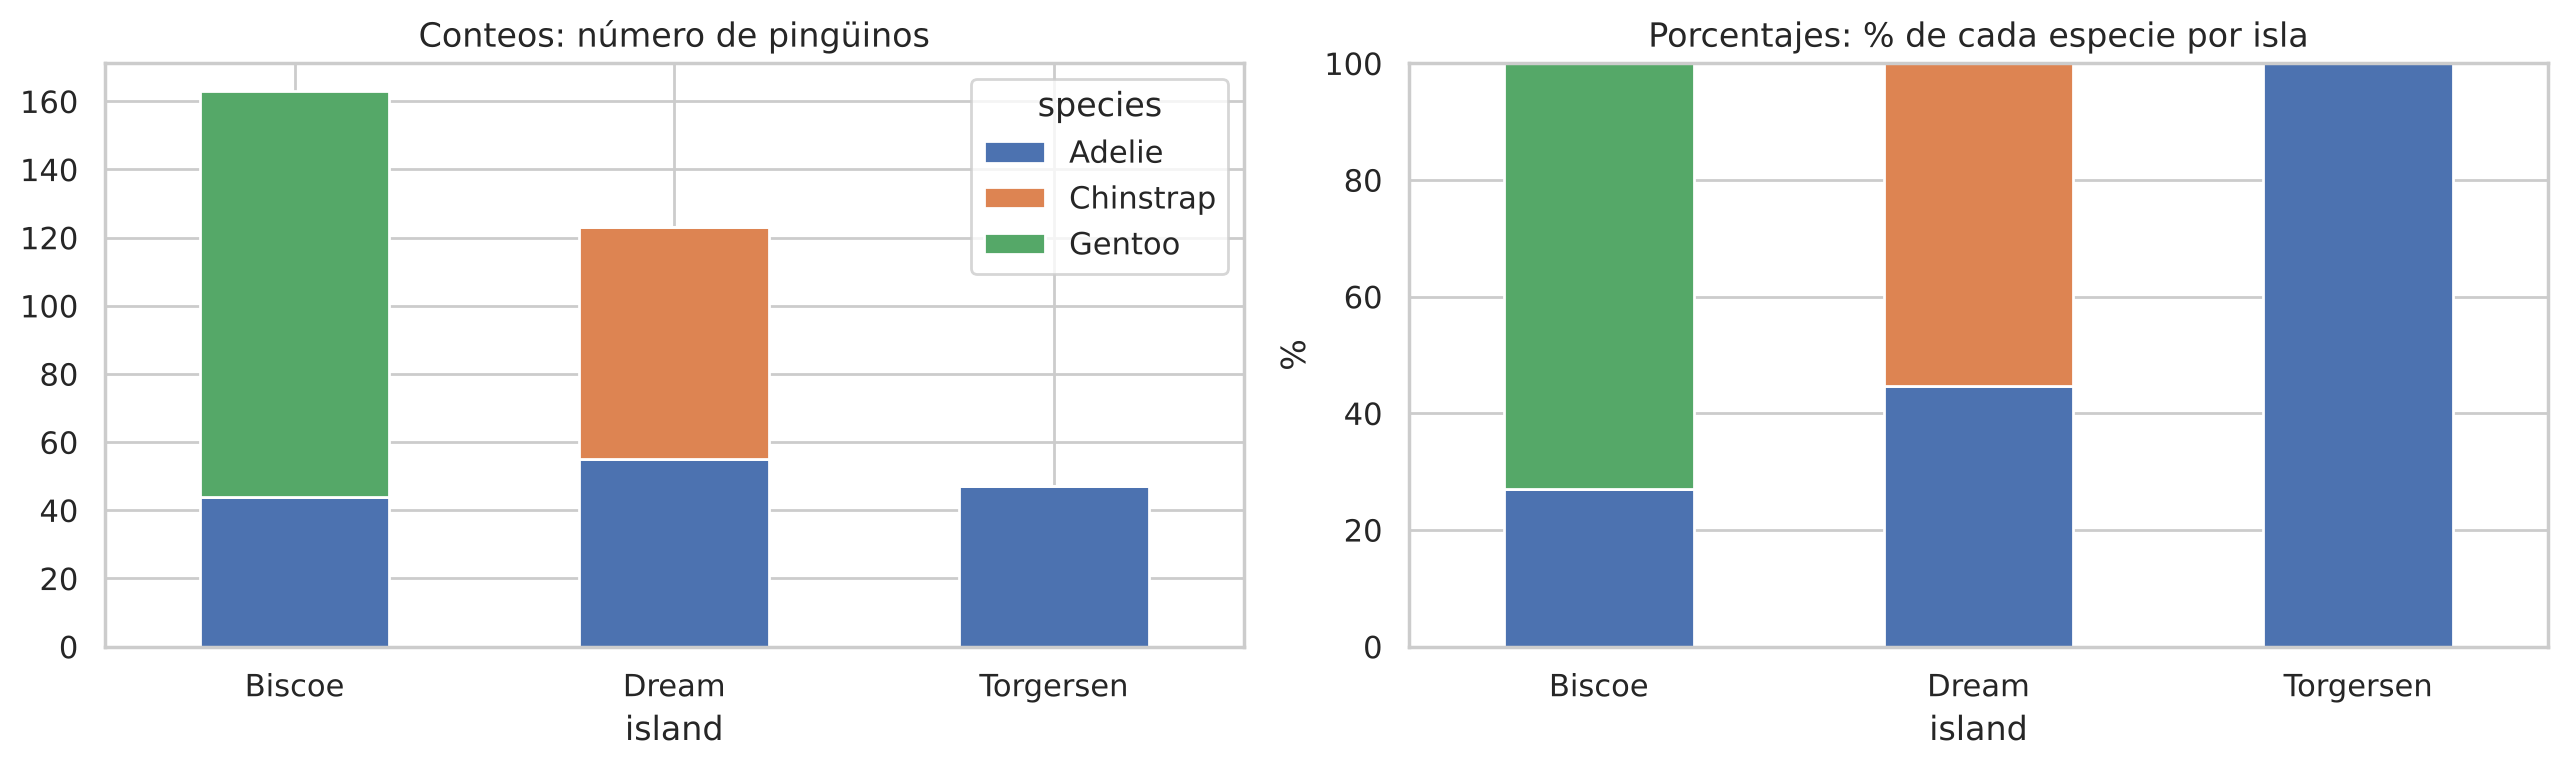

In [9]:
tabla = pd.crosstab(penguins["island"], penguins["species"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
tabla.plot.bar(stacked=True, rot=0, ax=axes[0], title="Conteos: número de pingüinos")
(tabla.div(tabla.sum(axis=1), axis=0) * 100).plot.bar(stacked=True, rot=0, ax=axes[1], legend=False,
                                                       title="Porcentajes: % de cada especie por isla")
axes[1].set_ylabel("%")
plt.tight_layout(); plt.show()

## 5. Interactividad con Plotly Express y lectura analítica
`hover` para detalle, **zoom**, clic en la leyenda para filtrar, exportar a HTML para compartir.

In [10]:
fig = px.scatter(penguins, x="flipper_length_mm", y="body_mass_g", color="species", symbol="sex",
                 hover_data=["island", "bill_length_mm", "bill_depth_mm"],
                 labels={"flipper_length_mm": "Largo de aleta (mm)", "body_mass_g": "Masa corporal (g)"},
                 title="Los Gentoo son los más grandes: aleta y masa crecen juntas")
fig.update_traces(marker=dict(size=8, opacity=0.75))
fig.write_html("penguins_interactivo.html")
fig.show()

### Cómo escribir un hallazgo
Un buen hallazgo es **específico, cuantificado y prudente**:

1. *Los Gentoo pesan en promedio ~1,4 kg más que Adelie y Chinstrap.*
2. *Aleta y masa tienen correlación de 0,87: los pingüinos con aletas largas pesan más.*
3. *Biscoe es la única isla donde viven Gentoo; Torgersen solo tiene Adelie.*

⚠️ **Correlación ≠ causalidad.** "Aleta y masa se mueven juntas" no implica que una cause la otra.

➡️ **Ahora: `S3_taller_estudiantes.ipynb` (45 min).**